calling GenPaths.py from: .../daaps/pythonModelling/DAAPS_TOOLKIT/GenPaths.py
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/FittingTools
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel
global path variables:
	 PROJECT_PATH =.../.../vera/daaps/pythonModelling/DAAPS_TOOLKIT
	 OPTICS_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA
	 LITERATURE_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/literatureDATA
	 VERA_DATA_PATH =.../.../projects/vera/daaps/veraData
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'printMembers']


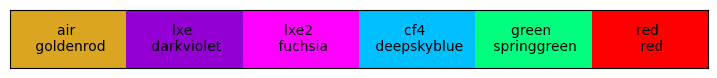

In [1]:
import numpy as np

import sys
sys.path.append('..')
from DAAPS_TOOLKIT.GenPaths import *

import PDEModel.MathEquations as ME
from PDEModel.OpticsDataLoader import *
import PDEModel.PDEStyle as MS
from PDEModel.PhotonInfo import * # this calls DataLoader when defining init
from PNJunction import * 

MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like
ms.SetMPLcolors()

rad2deg = 180/np.pi

---
### Diffusion as a 'integrated sphere' across $dp^*$

Volume of a spherical cap:
$$ V_{cap}(h) = \frac{\pi h^2}{3} (3R-h) $$
$$ V_{cap}(h\rightarrow 0) = 0 $$
$$ V_{cap}(h\rightarrow 2R) = \frac{4}{3}\pi R^3 $$
$$ f_s(h) \equiv \frac{V_{cap}(h)}{V_{sphere}} = \frac{\frac{\pi h^2}{3} (3R-h)}{\frac{4}{3}\pi R^3} = \frac{h^2(3R-h)}{4R^3}$$
$$ f_s(h\rightarrow 0) = 0 $$
$$ f_s(h\rightarrow 2R) = 1 $$

In [2]:
def CapFraction(h, R, shift=0):
    return h**2 * (3*R-h) / (4*R**3)

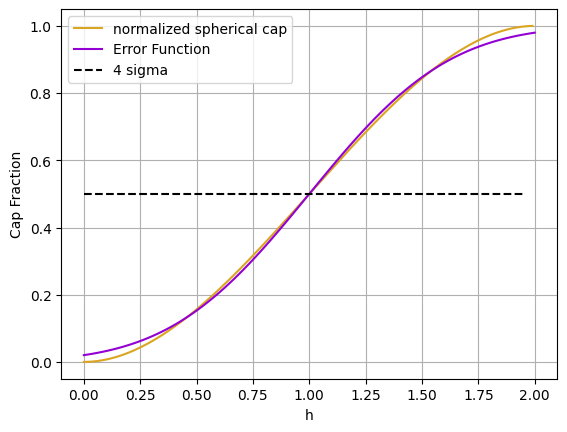

In [3]:
Rs = 1
hvals = np.arange(0, 2*Rs, 0.01)

f_sphere = CapFraction(h=hvals, R=Rs)
plt.plot(hvals, f_sphere, label='normalized spherical cap')

import scipy.special as sp
import scipy.integrate as intgl

x_values = np.linspace(0, 2, 100)
mean=Rs
sigma=Rs/2.05
# Compute the error function
z = (x_values - mean) / (np.sqrt(2) * sigma)
errorFunc = 0.5 * (mean + sp.erf(z))

plt.plot(x_values, errorFunc, label='Error Function')

plt.hlines(0.5, 0, 4*sigma, color='k', linestyle='--', label='4 sigma')

plt.xlabel('h')
plt.ylabel('Cap Fraction')
plt.grid()
plt.legend()

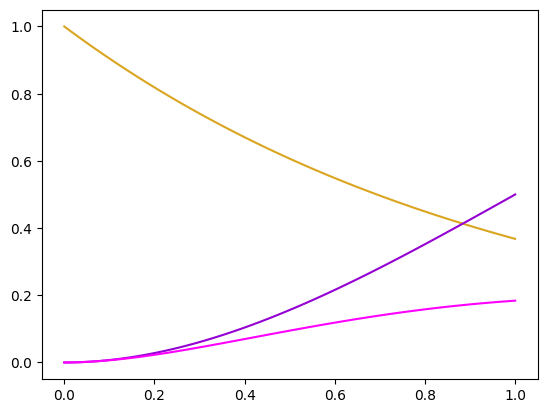

In [4]:
def expAbs(x, alpha=1):
    return alpha*np.exp(-alpha*x)

xVals = np.linspace(0, Rs, 100)
yVals = expAbs(xVals, alpha=1)

plt.plot(xVals, yVals, label='Exponential Decay')


capFrac = CapFraction(h=xVals, R=Rs)
plt.plot(xVals, capFrac, label='Cap Fraction')

weightedAbs = yVals * capFrac
plt.plot(xVals, weightedAbs, label='Weighted Absorption')


expIntegral = intgl.trapz(yVals, xVals)



---
### Maxwell boltzmann 3d random walk

A 3d random walk has the following MB distribution:

$$ f_R(r) = \sqrt{\frac{2}{\pi}} \frac{r^2}{\sigma^3} e^{-\frac{r^2}{2\sigma^2}} $$
$$ \sigma = <R>\sqrt{\frac{2}{3}} $$

In [5]:
def rWalk_3d_mb(r, R):
    sigma = R / np.sqrt(3/2)
    return np.sqrt(2/np.pi) * (r**2 * sigma**-3) * np.exp(-r**2 / (2*sigma**2))

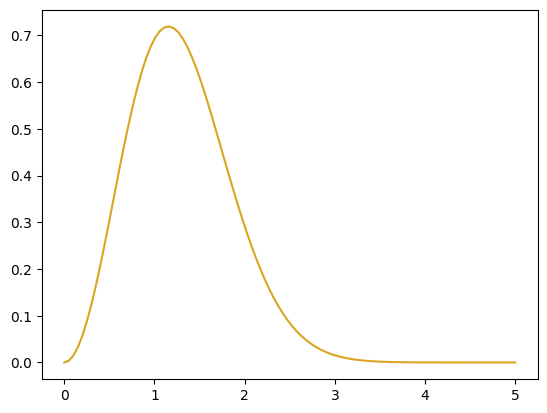

In [6]:
xvals = np.linspace(0, 5*Rs, 100)
plt.plot(xvals, rWalk_3d_mb(xvals, Rs), label='3D Random Walk')

---
### Gaussian approximation


We will **assume** that the 3d integral of the MB CDF (above) will look like some kind of gaussian with a characteristic width $\sigma$. this becomes the error function that we use to weight the photon absorption, in the region from $d_p'$-Rd to $d_p'$ where $d_p'$ is the value, approximating $d_p$, that $F(x=d_p')\rightarrow 1$ and $P_e(x=d_p') \approx P_e(x=X_{PN})$

#### Photo-Absorption basics
Starting from the Beer lambert law we can find the attenuation function (and you can derive $I(x) = I_0 e^{-\alpha x}$ starting from the differential equation $dI = -\alpha I dx$)
We find the differential form by taking the derivative of the exponential function wrt x:
$$
\begin{align*}

\frac{d I(x)}{dx} &= \frac{d}{dx} I_0e^{-\alpha x} \\
&= -\alpha I_0 e^{-\alpha x} \\
\end{align*}
$$
We can let $I_0=1$ and the rate be positive (we know we are attenuating)

The (unweighted) photon absorption in the P+ region ($d_p < x < X_{PN}$) is the integral of the exponential absorption/attenuation function:
$$
\begin{align*}
W_p(d_{p^*} < x < X_{PN}) &= \int_{d_{p^*}}^{X_{PN}} \alpha e^{-\alpha x} dx \\
&= \left[ -e^{-\alpha x} \right]_{d_{p^*}}^{X_{PN}} \\
&= e^{-\alpha d_{p^*}} - e^{-\alpha X_{PN}} \\
\end{align*}
$$

To write this more clearly: $\quad X_{PN} = X_{PN} + d_{p^*} - d_{p^*}$
$$
\begin{align*}
W_p(d_{p^*} < x < X_{PN}) &= e^{-\alpha d_{p^*}} - e^{-\alpha (X_{PN} + d_{p^*} - d_{p^*})} \\
&= e^{-\alpha d_{p^*}} - e^{-\alpha d_{p^*}} e^{-\alpha (X_{PN} - d_{p^*})} \\
&= e^{-\alpha d_{p^*}} \left[ 1 - e^{-\alpha (X_{PN} - d_{p^*})} \right]
\end{align*}
$$


#### Gaussian approximation to diffusion sphere overlap
We can approximate the overlap of the diffusion sphere with the P+ region as a gaussian with a characteristic width $\sigma_D$. This is probably not quite accurate. The problem with the 'hard sphere' model is following it strictly, you get a step function at $x=d_p$ from 0.5 to 1.0 when the e/h pair are created in the non-zero field region. Realistically the diffusion sphere is a PDF and as the interaction point approaches $d_p$ the probability of diffusion entering the P+ region approaches 1.0. Let us hope this complicted 3d integral of the MB radial PDF looks something like a gaussian. In reality it will have a longer tall at $x$ far from $d_p$ and may rise faster than the error func if the diffusion is a 'tight circle'. This gaussian is 'like' the hard-sphere model but it is shifted 'back' in space where $f(x)\rightarrow 1$ at $x=d_p$ is not the same as 0.5 for the hard sphere model. The gaussian is a 'soft' sphere model shifted back in space (which hopefully mimics the real MD diffusion).

To weight the photo absorption we will use an error function that spans 0-1 in height. This is the effective probability of diffusion past $d_p$ for absorption at x. The INTEGRAL of the error function does not need to be normalized?. We will call $d_p \approx d_p'$ the region where $f(x=d_p')\rightarrow 1$, equivalently this is the region where $P_e(x=d_p') \approx P_e(x=X_{PN})$

The error function will have some width $\sigma_D$ corresponding to a diffusion radius, and will be centered on $d_p - 2.5 \sigma_D$:

$$ \mu_g = d_p - 2.5\sigma_D $$

$$ f_g(x) = \frac{1}{2} \left[ 1 + erf\left( \frac{x - (d_p - 3\sigma_D)}{\sigma_D \sqrt{2}} \right) \right] $$

Now we can begin the absorption integral over the entire front of the junction:
$$
\begin{align*}
W_p(0 < x < X_{PN}) &= \int_{0}^{X_{PN}} f_g(x) \alpha e^{-\alpha x} dx \\
\end{align*}
$$


Xpn = 300nm, dp = 15nm, sigmaD = 2nm, alpha = 0.1 1/nm
check. Wp: 0.22313016014833625
check, Wp: 0.22313016014833623
dp=15nm, sigmaD=2nm 0.6183571559585086
dp*=2nm, sigmaD= OFF 0.8187307530778886
dp=15nm, sigmaD=2nm 0.37531108775801736


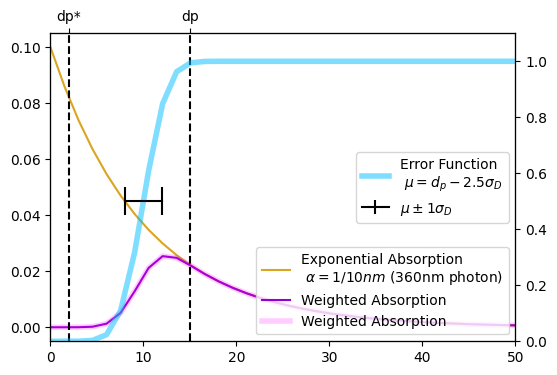

In [7]:
sp.erf(-100)

def errorFunc_cdf(x, mean, sigma):
    return 0.5 * (1 + sp.erf((x - mean) / (np.sqrt(2) * sigma)))

def WeightedAbsorption(x, alpha, dp, sigmaD, sigmaOffset = 2.5, turnOff=False):
    abs = expAbs(x, alpha)
    err = errorFunc_cdf(x, mean=dp - sigmaOffset*sigmaD, sigma=sigmaD)
    if turnOff or sigmaD is None or sigmaD == 0:
        return abs
    return abs * err

def IntegratedAbsorption(alpha, dp, sigmaD, Xpn, sigmaOffset = 2.5, turnOff=False):
    
    if turnOff: # integrage from dp to Xpn
        return intgl.quad(lambda x: expAbs(x, alpha), dp, Xpn)[0]
    
    # else integrage from 0 to Xpn weighted by the error function
    return intgl.quad(lambda x: WeightedAbsorption(x, alpha, dp, sigmaD, sigmaOffset, turnOff=turnOff), 0, Xpn)[0]

alpha350 = 1/10 #1/nm
dp = 15
dp_star = 2
Xpn = 300
sigmaD = 2
xVals = np.linspace(0, Xpn, 200)

fig, ax1 = plt.subplots(1, 1, figsize=(6, 4))

axt = ax1.twinx()
axt.vlines([dp_star, dp, Xpn], 0, 1.1, color='k', linestyle='--')

# axt.hlines(0.5, 0, 2*sigmaD, color='k', linestyle='-', label=r'$2\cdot\sigma_D$')
axt.errorbar([dp-3.5*sigmaD, dp - 1.5*sigmaD], [0.5, 0.5], yerr=0.05, linestyle = "-", color='k', label=r'$\mu \pm 1\sigma_D$')

axt.plot(xVals, errorFunc_cdf(xVals, mean=dp - 2.5*sigmaD, sigma=sigmaD), 
         color=ms.cf4.col, linewidth=4, alpha=0.5, label=f'Error Function\n $\mu=d_p-2.5\sigma_D$')

ax1.plot(xVals, expAbs(xVals, alpha=alpha350), label=f'Exponential Absorption\n $ \\alpha=1/10nm$ (360nm photon)')
ax1.plot(xVals, WeightedAbsorption(xVals, alpha=alpha350, dp=dp, sigmaD=sigmaD), label='Weighted Absorption')
ax1.plot(xVals, WeightedAbsorption(xVals, alpha=alpha350, dp=0, sigmaD=sigmaD, sigmaOffset=-5), alpha=0.2, linewidth=4, label='Weighted Absorption')
# ax1.plot(xVals, WeightedAbsorption(xVals, alpha=alpha350, dp=dp, sigmaD=sigmaD, turnOff=True), label='Weighted Absorption')

axtop = ax1.twiny()
axtop.set_xticks([2, dp, Xpn])
axtop.set_xticklabels(["dp*", "dp", "Xpn"])
axtop.set_xlim(ax1.get_xlim())


ax1.set_xlim(0, 50)
axtop.set_xlim(0, 50)
ax1.legend(loc='lower right')
axt.legend(loc = 'center right')

axt.set_ylim(0, 1.1)

# Absorption values with and without the diffusion
print(f"Xpn = {Xpn}nm, dp = {dp}nm, sigmaD = {sigmaD}nm, alpha = {alpha350} 1/nm")
print("check. Wp:", ME.Abs_layers(d_above = dp, d_region = Xpn-dp, mu=alpha350))
print("check, Wp:", IntegratedAbsorption(alpha=alpha350, dp=dp, sigmaD=sigmaD, Xpn=Xpn, turnOff=True))

print(f"dp={dp}nm, sigmaD={sigmaD}nm", IntegratedAbsorption(alpha=alpha350, dp=0+5*sigmaD, sigmaD=sigmaD, Xpn=Xpn))

print(f"dp*={2}nm, sigmaD= OFF", IntegratedAbsorption(alpha=alpha350, dp=dp_star, sigmaD=None, Xpn=Xpn, turnOff=True))
print(f"dp={dp}nm, sigmaD={sigmaD}nm", IntegratedAbsorption(alpha=alpha350, dp=dp, sigmaD=sigmaD, Xpn=Xpn))

# print(IntegratedAbsorption(alpha=alpha350, dp=dp, sigmaD=sigmaD, Xpn=Xpn))
